# Training notebook for Audio Files(ANN, CNN)

## Notebook Summary
1. Load all the .wav audio files
2. Extract MFCCs from each audio files
3. Create a DataFrame with MFCC and it's respective label
3. Train an ANN on the MFCC on MFCC df
4. Extract Mel Spectogram from Audio files and store it as tensor of image tensors
5. Evaluate the ANN
6. Train a CNN on the Mel Spectograms
7. Evaluate the CNN


## Install Libraries

In [ ]:
!pip install librosa soundfile audioread resampywandb_v1_NcoDhqHyXj5v0RPsi7iTslttcVc_wfYyv1mrSbTWR0HiEdYhFiFNp0oRf63q1rwChQZG5UB1AzHVh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 31.2 MB/s eta 0:00:00


## Obvious Setups

In [ ]:
import os
from itertools import cycle

import librosa
import soundfile as sf

from IPython.display import Audio, display

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from glob import glob

# import resampy



In [ ]:
from google.colab import drive

drive.mount('/content/drive')

RAW_DIR = "/content/drive/MyDrive/AnimalSoundDataset/raw"
PROCESSED_DIR = "/content/drive/MyDrive/AnimalSoundDataset/preprocessed_clips"

Mounted at /content/drive


# WandB Setup

In [ ]:
!pip install wandb

In [ ]:
!wandb login

wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter: 
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: shettyshivam (shivamshetty) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [ ]:
# Define W&B project details
WANDB_ENTITY = "shivamshetty"
WANDB_PROJECT_NAME = "AudioClassification"

In [ ]:
import random

import wandb

# The previous wandb.init() call and simulated training have been commented out.
# W&B runs will now be initialized directly before each model's training loop
# to track their specific configurations and metrics.

## Check Sample File

In [ ]:
audio_files = glob(os.path.join(PROCESSED_DIR, "*/*.wav"))

In [ ]:
sample_filename=audio_files[0]
print(sample_filename)

/content/drive/MyDrive/AnimalSoundDataset/preprocessed_clips/wild_boar/XC992312 - Eurasian Wild Pig - Sus scrofa_0.wav


In [ ]:
plt.figure(figsize=(14, 5))
Audio(sample_filename)

<Figure size 1400x500 with 0 Axes>

In [ ]:

class_counts = {}
for class_folder in os.listdir(PROCESSED_DIR):
    class_path = os.path.join(PROCESSED_DIR, class_folder)
    if os.path.isdir(class_path):
        wav_files = glob(os.path.join(class_path, '*.wav'))
        class_counts[class_folder] = len(wav_files)

# Create a DataFrame for easier plotting
df_class_counts = pd.DataFrame(class_counts.items(), columns=['Class', 'Number of Files'])
df_class_counts

,Class,Number of Files
0,wild_boar,575
1,peacock,110
2,noise,0
3,monkey,140


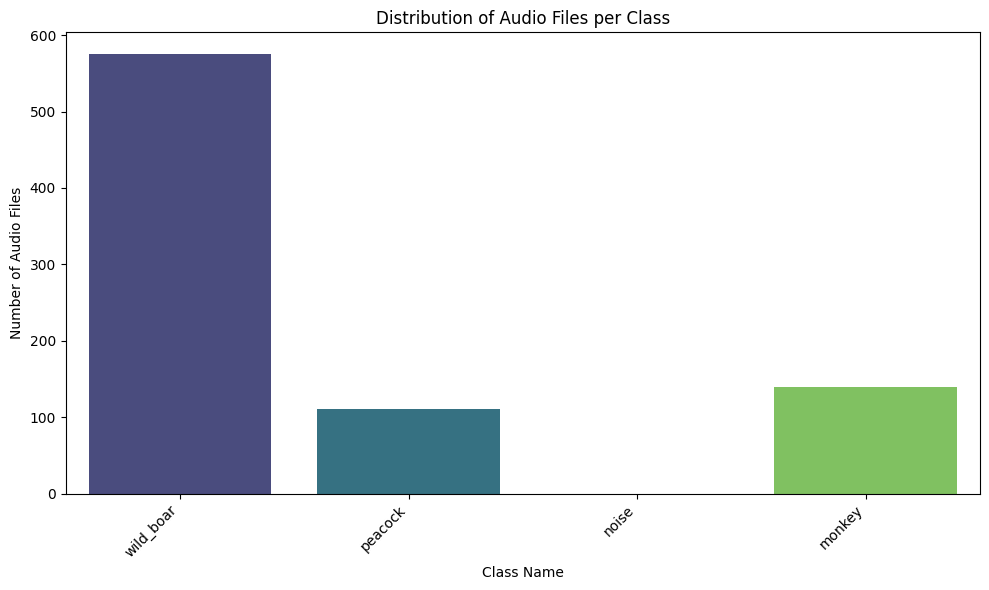

In [ ]:
# Visualize the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x='Class', y='Number of Files', data=df_class_counts, palette='viridis', hue='Class', legend=False)
plt.title('Distribution of Audio Files per Class')
plt.xlabel('Class Name')
plt.ylabel('Number of Audio Files')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## MFCC

In [ ]:
def features_extractor(file):
    audio, sample_rate = librosa.load(file, res_type='kaiser_fast')
    mfccs_features = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
    mfccs_scaled_features = np.mean(mfccs_features.T, axis=0)
    return mfccs_scaled_features

In [ ]:
import numpy as np
from tqdm import tqdm
extracted_features=[]
for file_name in tqdm(audio_files):
    class_name = os.path.basename(os.path.dirname(file_name))
    data=features_extractor(file_name)
    extracted_features.append([data,class_name])

100%|██████████| 825/825 [02:21<00:00,  5.84it/s]


In [ ]:
extracted_features_df=pd.DataFrame(extracted_features,columns=['feature','class'])
extracted_features_df.head()

,feature,class
0,"[-418.11078, 129.35371, -59.279728, 10.698485,...",wild_boar
1,"[-360.30728, 123.75827, -112.883736, -9.21897,...",wild_boar
2,"[-481.13434, 155.8102, -64.480034, 28.884314, ...",wild_boar
3,"[-284.10095, 109.06407, -134.67697, -8.590573,...",wild_boar
4,"[-407.62778, 100.324005, -64.816765, -20.61124...",wild_boar


In [ ]:
X=np.array(extracted_features_df['feature'].tolist())
y=np.array(extracted_features_df['class'].tolist())

In [ ]:
X.shape

(825, 40)

In [ ]:
y

array(['wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar',
       'wild_boar', 'wild_boar', 'wild_boar', 'wild_boar', 'wild

In [ ]:
import tensorflow
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(y))
class_names = labelencoder.classes_

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=0)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout,Activation,Flatten
from tensorflow.keras.optimizers import Adam
from sklearn import metrics
from wandb.integration.keras import WandbCallback

In [ ]:
num_labels=y.shape[1]

In [ ]:
ann_mfcc_model=Sequential()

ann_mfcc_model.add(Input((40,)))
ann_mfcc_model.add(Dense(100))
ann_mfcc_model.add(Activation('relu'))
ann_mfcc_model.add(Dropout(0.5))

ann_mfcc_model.add(Dense(200))
ann_mfcc_model.add(Activation('relu'))
ann_mfcc_model.add(Dropout(0.5))

ann_mfcc_model.add(Dense(100))
ann_mfcc_model.add(Activation('relu'))
ann_mfcc_model.add(Dropout(0.5))

ann_mfcc_model.add(Dense(num_labels))
ann_mfcc_model.add(Activation('softmax'))

In [ ]:
ann_mfcc_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │         4,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           303 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 3)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,703 (174.62 KB)

 Trainable params: 44,703 (174.62 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
ann_mfcc_model.compile(loss='categorical_crossentropy',metrics=['accuracy'],optimizer='adam')

In [ ]:
from datetime import datetime

num_epochs = 100
num_batch_size = 32

# Define hyperparameters for ANN
ann_config = {
    "model_type": "ANN_MFCC",
    "num_epochs": num_epochs,
    "batch_size": num_batch_size,
    "optimizer": "adam",
    "loss_function": "categorical_crossentropy",
    "dense_layers": [100, 200, 100],
    "dropout_rate": 0.5,
    "input_features": X_train.shape[1] # Number of MFCC features
}

# Initialize W&B run for ANN
wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT_NAME,
    config=ann_config,
    name="ANN_MFCC_Training"
)

start = datetime.now()

ann_mfcc_model.fit(
    X_train, y_train,
    batch_size=num_batch_size,
    epochs=num_epochs,
    validation_data=(X_test, y_test),
    verbose=1,
    callbacks=[WandbCallback()] # Add WandbCallback here
)

duration = datetime.now() - start
print("Training completed in time: ", duration)

# Evaluate the model and log final metrics to W&B
loss, accuracy = ann_mfcc_model.evaluate(X_test, y_test, verbose=0)
wandb.log({"final_test_loss": loss, "final_test_accuracy": accuracy})
print(f"Final ANN Test Accuracy: {accuracy:.4f}")

# Finish the W&B run
wandb.finish()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: shettyshivam (shivamshetty) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: WARNING WandbCallback is deprecated and will be removed in a future release. Please use the WandbMetricsLogger, WandbModelCheckpoint, and WandbEvalCallback callbacks instead. See https://docs.wandb.ai/guides/integrations/keras for more information.
wandb: WARNING The save_model argument by default saves the model in the HDF5 format that cannot save custom objects like subclassed models and custom layers. This behavior will be deprecated in a future release in favor of the SavedModel format. Meanwhile, the HDF5 model is saved as W&B files and the SavedModel as W&B Artifacts.


Epoch 1/100


AttributeError: 'Node' object has no attribute 'inbound_layers'

In [ ]:
# The ANN model evaluation is now handled within the training cell (Kc5I2XRnZXVc)
# and metrics are logged to Weights & Biases.

In [ ]:
audio, sample_rate = librosa.load(sample_filename, res_type='kaiser_fast')
mfccs_features = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
mfccs_scaled_features = np.mean(mfccs_features.T,axis=0)

print(mfccs_scaled_features)
mfccs_scaled_features=mfccs_scaled_features.reshape(1,-1)
print(mfccs_scaled_features)
print(mfccs_scaled_features.shape)
pred=ann_mfcc_model.predict(mfccs_scaled_features)
print("softmax o/p", pred)
predicted_index = np.argmax(pred, axis=1)
predicted_class = [class_names[i] for i in predicted_index]
print("predicted_class", predicted_class)

Spectogram

In [ ]:
def extract_spectogram_features(file_path):
    audio, sr = librosa.load(file_path, sr=22050)
    spec = librosa.stft(y)
    spec_db = librosa.amplitude_to_db(np.abs(spec), ref=np.max)
    return spec_db

## Mel Spectogram

In [ ]:
max_len = 200

def pad_or_trim(mel, max_len):

    if mel.shape[1] < max_len:
        pad_width = max_len - mel.shape[1]
        mel = np.pad(mel, ((0,0),(0,pad_width)), mode='constant')

    else:
        mel = mel[:, :max_len]

    return mel

In [ ]:
def extract_mel_features(file_path):
    audio, sr = librosa.load(file_path, sr=22050)

    mel_spec = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_mels=128
    )

    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

    mel = pad_or_trim(mel_spec_db, 200)

    return mel

In [ ]:
X_mel = []
y_mel = []
for file_name in tqdm(audio_files):
    class_name = os.path.basename(os.path.dirname(file_name))
    data=extract_mel_features(file_name)
    X_mel.append(data)
    y_mel.append(class_name)

In [ ]:
X_mel = tensorflow.image.resize(
    np.stack([x[..., np.newaxis] for x in X_mel]),
    (128,128)
).numpy()
X_mel.shape


In [ ]:
labelencoder=LabelEncoder()
y_mel=to_categorical(labelencoder.fit_transform(y_mel))
class_names = labelencoder.classes_

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X_mel,y_mel,test_size=0.2,random_state=0)

In [ ]:
X_mel_img =  tensorflow.image.resize(X_mel, (128, 128))

In [ ]:
X_mel_img.shape

In [ ]:
from tensorflow.keras import layers, models
cnn_mel_model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128,128,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation='softmax')
])

cnn_mel_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
cnn_mel_model.summary()

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Define hyperparameters for CNN (Mel)
cnn_mel_config = {
    "model_type": "CNN_MelSpectrogram",
    "num_epochs": 20, # Max epochs, but early stopping will determine actual
    "batch_size": 32,
    "optimizer": "adam",
    "loss_function": "categorical_crossentropy",
    "conv_layers": [32, 64, 128, 256],
    "dropout_rate": 0.4,
    "input_shape": X_train.shape[1:], # e.g., (128, 128, 1)
    "early_stopping_patience": 5
}

# Initialize W&B run for CNN (Mel)
wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT_NAME,
    config=cnn_mel_config,
    name="CNN_MelSpectrogram_Training"
)

history = cnn_mel_model.fit(
    X_train,
    y_train,
    epochs=cnn_mel_config["num_epochs"],
    batch_size=cnn_mel_config["batch_size"],
    validation_split=0.2,
    callbacks=[early_stop, WandbCallback()] # Add WandbCallback here
)

# Evaluate the model on the test set and log final metrics to W&B
loss, accuracy = cnn_mel_model.evaluate(X_test, y_test, verbose=0)
wandb.log({"final_test_loss": loss, "final_test_accuracy": accuracy})
print(f"Final CNN (Mel) Test Accuracy: {accuracy:.4f}")

# Finish the W&B run
wandb.finish()

In [ ]:
plt.figure()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()


In [ ]:
y_pred_probs = cnn_mel_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.argmax(y_test, axis=1)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print(cm)

In [ ]:
plt.figure()

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

### Audio Data Augmentation using Librosa

This section defines a function to perform common audio augmentations: time stretching, pitch shifting, and adding white noise. After augmentation, Mel spectrograms are re-extracted from the modified audio, ensuring consistency with your existing feature extraction pipeline.

In [ ]:
def augment_audio_and_extract_mel(file_path, original_label, sr=22050):
    augmented_mels = []
    augmented_labels = []

    # Load the original audio
    audio, _ = librosa.load(file_path, sr=sr)

    # 1. Original (unaugmented) data
    mel_original = extract_mel_features(file_path)
    augmented_mels.append(mel_original)
    augmented_labels.append(original_label)

    # 2. Time Stretching
    # Values less than 1.0 speed up, values greater than 1.0 slow down
    for rate in [0.9, 1.1]: # Speed up by 10%, slow down by 10%
        audio_stretch = librosa.effects.time_stretch(audio, rate=rate)
        # Save temporary file to use existing extract_mel_features function
        temp_path = file_path.replace('.wav', f'_stretch_{rate}.wav')
        sf.write(temp_path, audio_stretch, sr)
        mel_stretch = extract_mel_features(temp_path)
        augmented_mels.append(mel_stretch)
        augmented_labels.append(original_label)
        os.remove(temp_path) # Clean up temporary file

    # 3. Pitch Shifting
    # n_steps: number of semitones to shift
    for steps in [-2, 2]: # Shift down by 2 semitones, up by 2 semitones
        audio_pitch = librosa.effects.pitch_shift(y=audio, sr=sr, n_steps=steps)
        temp_path = file_path.replace('.wav', f'_pitch_{steps}.wav')
        sf.write(temp_path, audio_pitch, sr)
        mel_pitch = extract_mel_features(temp_path)
        augmented_mels.append(mel_pitch)
        augmented_labels.append(original_label)
        os.remove(temp_path) # Clean up temporary file

    # 4. Adding White Noise
    # Adjust noise level as needed
    noise_level = 0.005 # Small amount of noise
    noise = np.random.randn(len(audio))
    audio_noise = audio + noise_level * noise
    temp_path = file_path.replace('.wav', f'_noise.wav')
    sf.write(temp_path, audio_noise, sr)
    mel_noise = extract_mel_features(temp_path)
    augmented_mels.append(mel_noise)
    augmented_labels.append(original_label)
    os.remove(temp_path) # Clean up temporary file

    return augmented_mels, augmented_labels


### Generating the Augmented Dataset

Now, we'll apply the `augment_audio_and_extract_mel` function to each of your original audio files to create a significantly larger dataset. We'll map the `audio_files` to their one-hot encoded `y_mel` labels for consistency.

In [ ]:
from sklearn.preprocessing import LabelEncoder

X_mel_augmented = []
y_mel_augmented = []

# Map original file paths to their one-hot encoded labels
# First, re-create the labelencoder and get class_names if not available from previous cells
labelencoder = LabelEncoder()
original_y_labels = [os.path.basename(os.path.dirname(f)) for f in audio_files]
labelencoder.fit(original_y_labels)
class_names = labelencoder.classes_

# Create a dictionary to easily lookup original one-hot encoded labels by class name
original_y_encoded = to_categorical(labelencoder.transform(original_y_labels), num_classes=len(class_names))

# Ensure `y_mel` from previous steps corresponds to `audio_files` in order
# For simplicity, we'll assume `y_mel` directly maps to `audio_files` one-to-one
# based on the order they were processed in `zQqueckTZ5I2`

for i, file_name in tqdm(enumerate(audio_files)):
    original_one_hot_label = y_mel[i] # Get the one-hot encoded label for this file

    # Augment audio and extract Mels
    mels, labels = augment_audio_and_extract_mel(file_name, original_one_hot_label)

    X_mel_augmented.extend(mels)
    y_mel_augmented.extend(labels)

# Convert lists to numpy arrays
X_mel_augmented = np.array(X_mel_augmented)
y_mel_augmented = np.array(y_mel_augmented)

# Resize the augmented Mel spectrograms to (128, 128, 1) if necessary
# This step was done on the original X_mel after extraction, so doing it here for augmented data
X_mel_augmented_resized = tensorflow.image.resize(
    np.stack([x[..., np.newaxis] for x in X_mel_augmented]),
    (128,128)
).numpy()

print(f"Original dataset size: {len(audio_files)}")
print(f"Augmented dataset size: {len(X_mel_augmented_resized)}")
print(f"Shape of augmented X_mel: {X_mel_augmented_resized.shape}")
print(f"Shape of augmented y_mel: {y_mel_augmented.shape}")

# Now, split the augmented dataset for training and testing
X_train_aug, X_test_aug, y_train_aug, y_test_aug = train_test_split(
    X_mel_augmented_resized, y_mel_augmented, test_size=0.2, random_state=0
)

print(f"Augmented training set size: {len(X_train_aug)}")
print(f"Augmented testing set size: {len(X_test_aug)}")


You now have `X_train_aug`, `X_test_aug`, `y_train_aug`, and `y_test_aug` which contain your original data plus several augmented versions. You can use these new datasets to train your enhanced CNN model.

Keep in mind that the `sf.write` and `os.remove` operations for temporary files can be slow. For very large datasets, you might consider processing and storing augmented features directly in memory or using a more efficient data loading pipeline.

In [ ]:
from tensorflow.keras import layers, models

cnn_mel_aug_model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128,128,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation='softmax')
])

cnn_mel_aug_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# This cell is redundant as the model was already compiled in Crd44BenOBTl.

In [ ]:
cnn_mel_aug_model.summary()

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Define hyperparameters for Augmented CNN (Mel)
cnn_mel_aug_config = {
    "model_type": "CNN_MelSpectrogram_Augmented",
    "num_epochs": 20, # Max epochs, but early stopping will determine actual
    "batch_size": 32,
    "optimizer": "adam",
    "loss_function": "categorical_crossentropy",
    "conv_layers": [32, 64, 128, 256], # Same as non-augmented CNN
    "dropout_rate": 0.4,
    "input_shape": X_train_aug.shape[1:], # e.g., (128, 128, 1)
    "early_stopping_patience": 5,
    "augmentation_methods": ["time_stretch", "pitch_shift", "white_noise"]
}

# Initialize W&B run for Augmented CNN (Mel)
wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT_NAME,
    config=cnn_mel_aug_config,
    name="CNN_MelSpectrogram_Augmented_Training"
)

history = cnn_mel_aug_model.fit(
    X_train_aug,
    y_train_aug,
    epochs=cnn_mel_aug_config["num_epochs"],
    batch_size=cnn_mel_aug_config["batch_size"],
    validation_split=0.2,
    callbacks=[early_stop, WandbCallback()] # Add WandbCallback here
)

# Evaluate the model on the augmented test set and log final metrics to W&B
loss, accuracy = cnn_mel_aug_model.evaluate(X_test_aug, y_test_aug, verbose=0)
wandb.log({"final_test_loss": loss, "final_test_accuracy": accuracy})
print(f"Final CNN (Augmented Mel) Test Accuracy: {accuracy:.4f}")

# Finish the W&B run
wandb.finish()

In [ ]:
y_pred_probs = cnn_mel_aug_model.predict(X_test_aug)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.argmax(y_test_aug, axis=1)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print(cm)

In [ ]:
plt.figure()

ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.setp(ax.get_xticklabels(), rotation=90, ha='right', rotation_mode='anchor')

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
labelencoder.classes_